In [11]:
# B5 - PHÁT HIỆN MÃ ĐỘC VỚI HỌC MÁY (CICMAL2017)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


In [12]:
# Đọc dữ liệu
df = pd.read_csv("Dataset/category_CICMAL2017_dataset.csv", low_memory=False)
print("Dataset shape:", df.shape)

Dataset shape: (25000, 71)


In [13]:
# Tách features và labels
X = df.drop(columns=['Flow ID', 'Src IP', 'Dst IP', 'Timestamp', 'Cat_Label', 'Binary Label'])
y = df['Binary Label']

In [14]:
# Mã hóa cột object
for col in X.select_dtypes(include='object').columns:
    X[col] = LabelEncoder().fit_transform(X[col].astype(str))


In [15]:
# Xử lý giá trị vô hạn và khuyết thiếu
X = X.replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy='median').fit_transform(X)

In [16]:
# Chuẩn hóa
X = StandardScaler().fit_transform(X)

In [17]:
# Chia tập train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Các mô hình
models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
}

In [24]:
# Cell huấn luyện
y_preds = {}
results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_preds[name] = y_pred

    results.append({
        'Mô hình': name,
        'Độ chính xác (%)': accuracy_score(y_test, y_pred) * 100,
        'Precision (%)': precision_score(y_test, y_pred) * 100,
        'Recall (%)': recall_score(y_test, y_pred) * 100,
        'Điểm F1 (%)': f1_score(y_test, y_pred) * 100
    })

BẢNG TỔNG HỢP KẾT QUẢ


,Mô hình,Độ chính xác (%),Precision (%),Recall (%),Điểm F1 (%)
0,Random Forest,98.22,97.85,99.98,98.90
1,Logistic Regression,97.64,97.27,99.85,98.54
2,Decision Tree,96.52,97.73,97.92,97.83


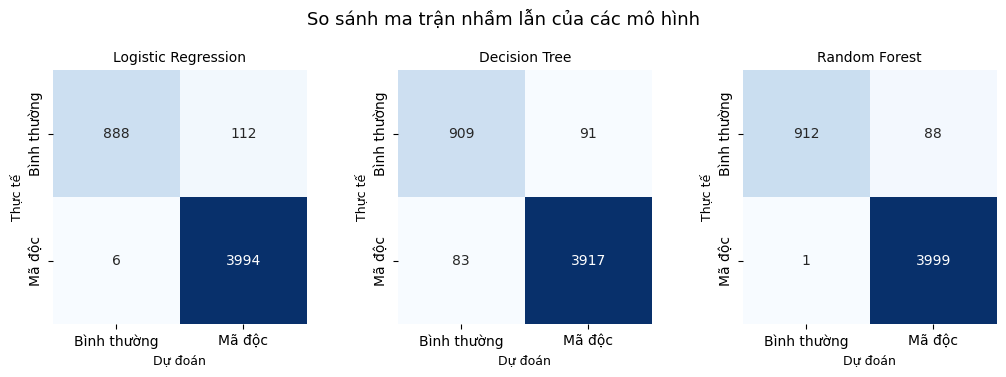

In [31]:
# ==========================================
# BẢNG TỔNG HỢP KẾT QUẢ
# ==========================================
results_df = pd.DataFrame(results).round(2)

# Sắp xếp theo F1-score giảm dần
results_df = results_df.sort_values(
    by='Điểm F1 (%)',
    ascending=False
).reset_index(drop=True)

print("BẢNG TỔNG HỢP KẾT QUẢ")
display(results_df)      # Jupyter Notebook

# ==========================================
# CONFUSION MATRIX TỔNG HỢP
# ==========================================
fig, axes = plt.subplots(
    1,
    len(y_preds),
    figsize=(3.5 * len(y_preds), 3.5)
)

# Trường hợp chỉ có 1 mô hình
if len(y_preds) == 1:
    axes = [axes]

for ax, (name, y_pred) in zip(axes, y_preds.items()):

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        square=True,
        ax=ax,
        xticklabels=['Bình thường', 'Mã độc'],
        yticklabels=['Bình thường', 'Mã độc']
    )

    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Dự đoán", fontsize=9)
    ax.set_ylabel("Thực tế", fontsize=9)

plt.suptitle(
    "So sánh ma trận nhầm lẫn của các mô hình",
    fontsize=13,
    y=1.02
)

plt.tight_layout()
plt.show()